In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Description des variables

Le jeu de données contient **1 000 trajets de taxi** décrits par **11 variables** : 10 variables explicatives et 1 variable cible (`Trip_Price`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Trip_Distance_km` | Numérique (continue) | Distance parcourue pendant le trajet, en kilomètres | 1,23 – 146,07 km (médiane ≈ 25,8) |
| `Time_of_Day` | Catégorielle | Moment de la journée où le trajet a lieu | `Morning`, `Afternoon`, `Evening`, `Night` |
| `Day_of_Week` | Catégorielle | Type de jour du trajet | `Weekday` (semaine), `Weekend` (week-end) |
| `Passenger_Count` | Numérique (discrète) | Nombre de passagers à bord | 1 – 4 |
| `Traffic_Conditions` | Catégorielle (ordinale) | Niveau de congestion du trafic | `Low`, `Medium`, `High` |
| `Weather` | Catégorielle | Conditions météorologiques pendant le trajet | `Clear` (dégagé), `Rain` (pluie), `Snow` (neige) |
| `Base_Fare` | Numérique (continue) | Tarif de prise en charge, fixe au démarrage de la course | 2,01 – 5,00 |
| `Per_Km_Rate` | Numérique (continue) | Tarif appliqué par kilomètre parcouru | 0,50 – 2,00 |
| `Per_Minute_Rate` | Numérique (continue) | Tarif appliqué par minute de trajet | 0,10 – 0,50 |
| `Trip_Duration_Minutes` | Numérique (continue) | Durée totale du trajet, en minutes | 5,01 – 119,84 min (médiane ≈ 61,9) |
| **`Trip_Price`** | Numérique (continue) | **Variable cible** : prix total payé pour la course | 6,13 – 332,04 (médiane ≈ 50,1) |


In [3]:
# Import les données
df = pd.read_csv("/content/drive/MyDrive/Machine Learning/REGRESSION/taxi_trip_pricing.csv")
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [4]:
# Dimension des données
df.shape

(1000, 11)

In [5]:
# Afficher les infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    object 
 2   Day_of_Week            950 non-null    object 
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    object 
 5   Weather                950 non-null    object 
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


### <font color = 'bisque'>Exploration et préparation des données

In [6]:
# sélection les variables quantitatives
quant_data = df[["Trip_Distance_km","Passenger_Count","Base_Fare","Per_Km_Rate","Trip_Duration_Minutes","Trip_Price"]]

In [7]:
# décrire les variables quantitatives
quant_data.describe()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Trip_Duration_Minutes,Trip_Price
count,950.000000,950.000000,950.000000,950.000000,950.000000,951.000000
mean,27.070547,2.476842,3.502989,1.233316,62.118116,56.874773
std,19.905300,1.102249,0.870162,0.429816,32.154406,40.469791
min,1.230000,1.000000,2.010000,0.500000,5.010000,6.126900
25%,12.632500,1.250000,2.730000,0.860000,35.882500,33.742650
50%,25.830000,2.000000,3.520000,1.220000,61.860000,50.074500
75%,38.405000,3.000000,4.260000,1.610000,89.055000,69.099350
max,146.067047,4.000000,5.000000,2.000000,119.840000,332.043689


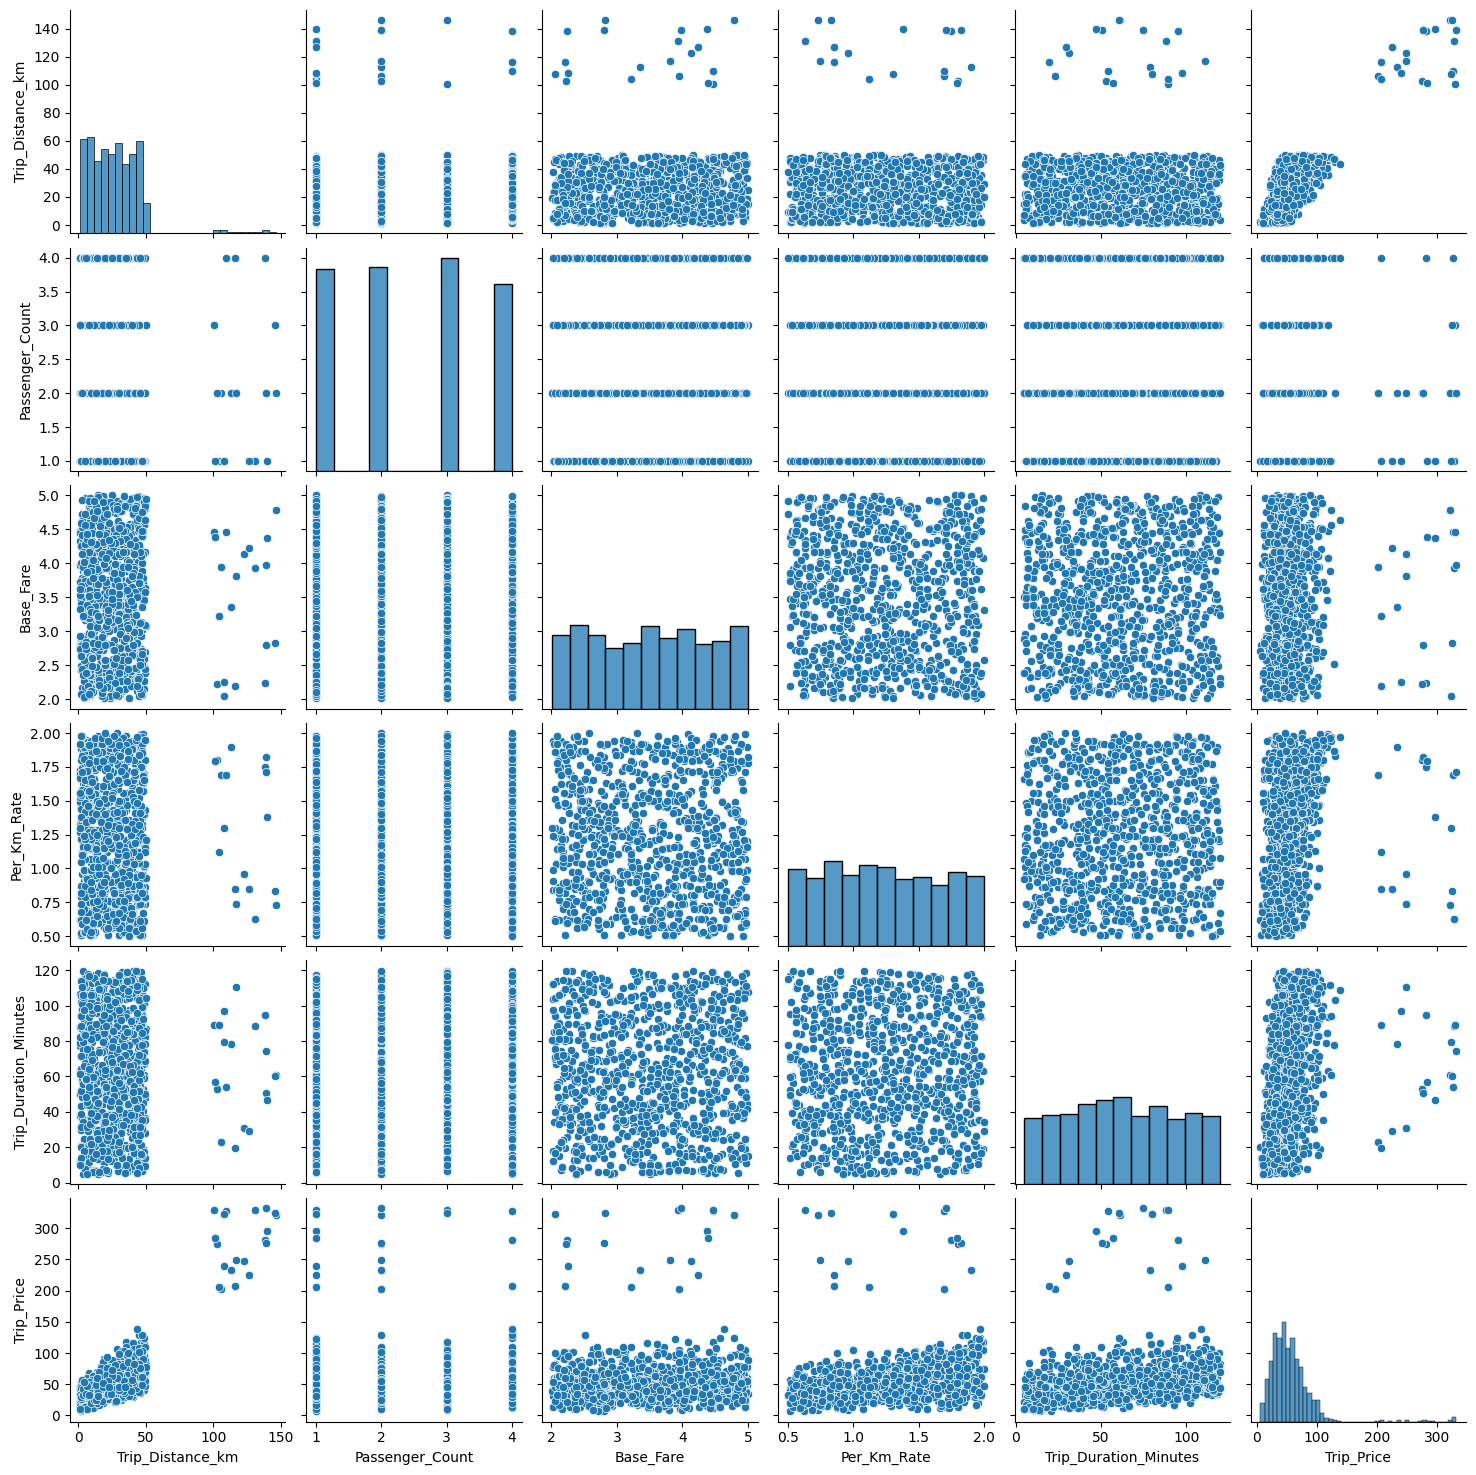

In [8]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [9]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df,x = col)
    fig.show()

In [10]:
# Appliquer la fonctions boxplot_func
for col in quant_data.columns:
  boxplot_func(col)

In [11]:
# Afficher la matrice de corrélation
quant_data.corr()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Trip_Duration_Minutes,Trip_Price
Trip_Distance_km,1.000000,-0.048397,0.032218,-0.017041,-0.022102,0.849123
Passenger_Count,-0.048397,1.000000,0.022932,0.030213,0.022845,-0.014223
Base_Fare,0.032218,0.022932,1.000000,0.003092,0.012035,0.035533
Per_Km_Rate,-0.017041,0.030213,0.003092,1.000000,0.027199,0.275135
Trip_Duration_Minutes,-0.022102,0.022845,0.012035,0.027199,1.000000,0.221211
Trip_Price,0.849123,-0.014223,0.035533,0.275135,0.221211,1.000000


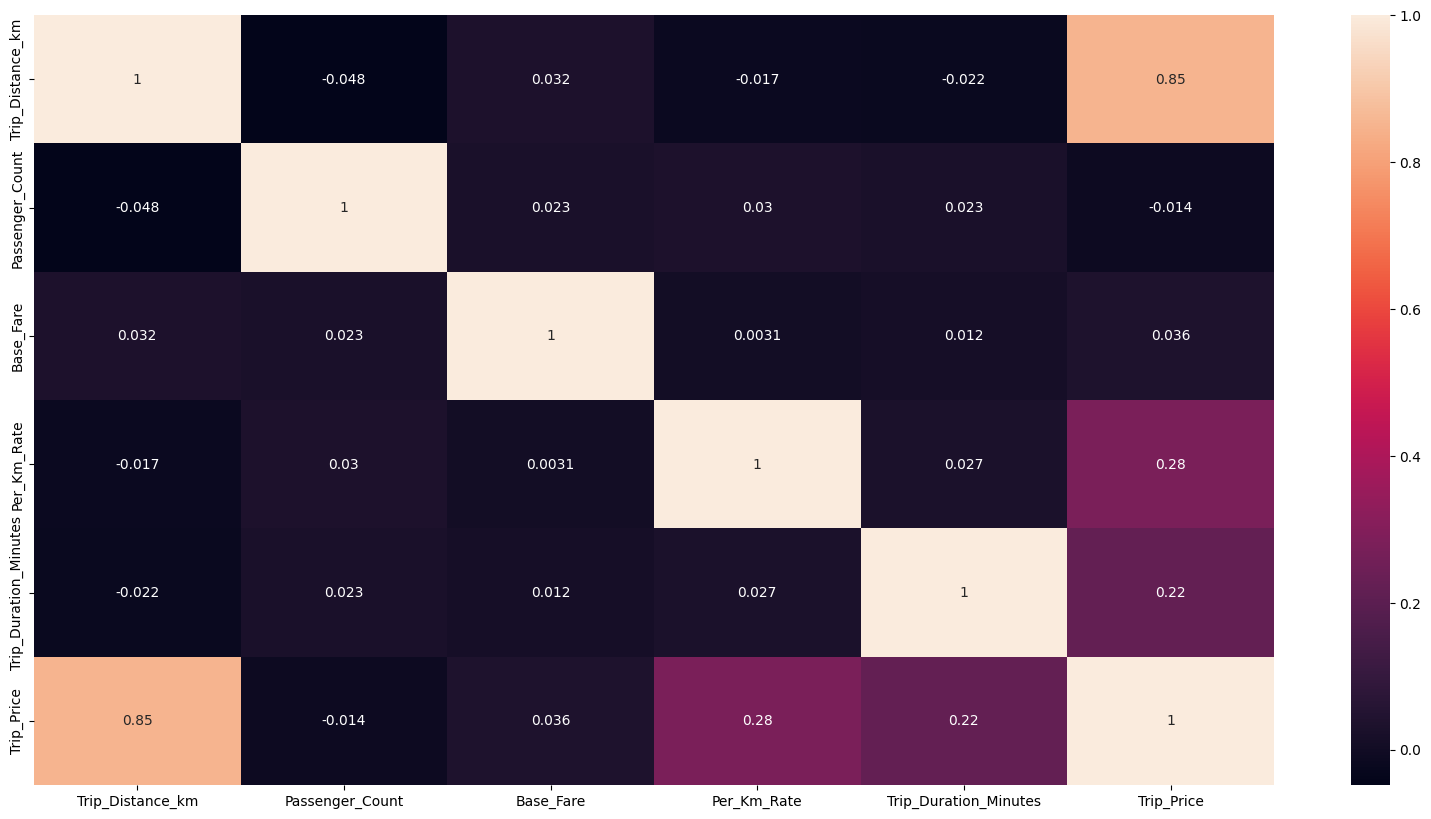

In [12]:
# Visualisaton le matrice de corrélation
plt.figure(figsize = (20, 10))
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [13]:
# sélection les variables catégorielles
cat_data = df.select_dtypes(include = "object")
cat_data.head()

,Time_of_Day,Day_of_Week,Traffic_Conditions,Weather
0,Morning,Weekday,Low,Clear
1,Afternoon,Weekday,High,Clear
2,Evening,Weekend,High,Clear
3,Evening,Weekday,Low,NaN
4,Evening,Weekday,High,Clear


In [14]:
# Faire un describre
cat_data.describe()

,Time_of_Day,Day_of_Week,Traffic_Conditions,Weather
count,950,950,950,950
unique,4,2,3,3
top,Afternoon,Weekday,Low,Clear
freq,371,655,397,667


In [15]:
# Fonction de visualisaion du counplot
def countplot_func(col):
    val = cat_data[col].value_counts()
    fig = px.bar(x = val.index, y = val.values,color = val.index.astype(str), text_auto = True)
    fig.show()

In [16]:
# Appliquer la fonction countplot_func
for i in cat_data.columns:
  countplot_func(i)

In [17]:
# Imputer les valeurs manquantes des variables catégorielle en utilisant le mode
for col in cat_data.columns:
  df.fillna({col: df[col].mode()[0]}, inplace = True)

In [18]:
df.isnull().sum()

,0
Trip_Distance_km,50
Time_of_Day,0
Day_of_Week,0
Passenger_Count,50
Traffic_Conditions,0
Weather,0
Base_Fare,50
Per_Km_Rate,50
Per_Minute_Rate,50
Trip_Duration_Minutes,50


In [19]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarde
import joblib as jb
jb.dump(uniques,"/content/drive/MyDrive/Machine Learning/REGRESSION/uniques.joblib")

['/content/drive/MyDrive/Machine Learning/REGRESSION/uniques.joblib']

In [22]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
encoders = []
for col in cat_data.columns:
    encoder = LabelEncoder()          # un nouvel encodeur par colonne
    df[col] = encoder.fit_transform(df[col])
    encoders.append(encoder)

In [23]:
# sauvegarde les encodeurs
jb.dump(encoders, "/content/drive/MyDrive/Machine Learning/REGRESSION/encoders.joblib" )

['/content/drive/MyDrive/Machine Learning/REGRESSION/encoders.joblib']

In [ ]:
from sklearn.impute import KNNImputer
# Imputer les valeurs manquantes des variables quantitatives
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

In [ ]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [ ]:
# Application du traitement
for i in df.select_dtypes(include = "number"):
  impute_func(df,i)


In [ ]:
# réafficher les boxplots
for col in df.select_dtypes(include = "number"):
  boxplot_func(col)

In [ ]:
# Fractionner les données
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [ ]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)

In [ ]:
# sauvegarde du scaler
jb.dump(scaler,"/content/drive/MyDrive/Machine Learning/REGRESSION/scaler.joblib")

['/content/drive/MyDrive/Machine Learning/REGRESSION/scaler.joblib']

In [ ]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

### <font color = 'bisque'>Multiple Linear Regression

1.   Élément de liste
2.   Élément de liste



In [ ]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False],
    'positive': [True, False]
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LinearRegression(),
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]})

In [ ]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

> Ajouter une citation



In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
# from math import *
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [ ]:
# Evalution
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f"R2:{r2_lr} -- MSE:  {mse_lr}, MAE {mae_lr}, MAE {rmse_lr}")

R2:0.864514089167485 -- MSE:  71.61888514466979, MAE 6.725709389585957, MAE 8.462794168870573


### <font color = 'bisque'>Ridge Regression

> Ajouter une citation



In [ ]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.linear_model import Ridge
# dictionnaire params
params_rr = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) #
 }
# Initialisation du modèle
rr = Ridge()
# Initialisation du GridSearchCV
grid_rr = GridSearchCV(rr, params_rr, cv = cv)
# Lancer la recherche
grid_rr.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Ridge(),
             param_grid={'alpha': array([1.00000000e-08, 1.45082878e-08, 2.10490414e-08, 3.05385551e-08,
       4.43062146e-08, 6.42807312e-08, 9.32603347e-08, 1.35304777e-07,
       1.96304065e-07, 2.84803587e-07, 4.13201240e-07, 5.99484250e-07,
       8.69749003e-07, 1.26185688e-06, 1.83073828e-06, 2.65608778e-06,
       3....
       8.49753436e+04, 1.23284674e+05, 1.78864953e+05, 2.59502421e+05,
       3.76493581e+05, 5.46227722e+05, 7.92482898e+05, 1.14975700e+06,
       1.66810054e+06, 2.42012826e+06, 3.51119173e+06, 5.09413801e+06,
       7.39072203e+06, 1.07226722e+07, 1.55567614e+07, 2.25701972e+07,
       3.27454916e+07, 4.75081016e+07, 6.89261210e+07, 1.00000000e+08]),
                         'fit_intercept': [True, False],
                         'positive': [True, False]})

In [ ]:
# Récupérer le modèle optimal en partant de gridsearch
rr_model = grid_rr.best_estimator_

#### <font color = 'teal'> Evaluation du Ridge<font>

In [ ]:
# Evaluation le modèle
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(rr_model)
print(f"R2:{r2_rr} -- MSE:  {mse_rr}, MAE {mae_rr}, MAE {rmse_rr}")

R2:0.8642675279829386 -- MSE:  71.7492192661194, MAE 6.733627977911116, MAE 8.470491087659521


### <font color = 'bisque'>Decision Tree Regressor<font>

> Ajouter une citation

> Ajouter une citation





In [ ]:
# Recherche des paramètres optimaux du decision tree
from sklearn.tree import DecisionTreeRegressor
# Dictionaire des params
params_dt = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Initialisation du modèle
dt = DecisionTreeRegressor(random_state = 42)
# Initialisation du GridSearchCV
grid_dt = GridSearchCV(dt, params_dt, cv = cv)
# Lancer la recherche
grid_dt.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])})

In [ ]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid_dt.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [ ]:
# Evaluation le modèle
r2_dt, mse_dt, mae_dt, rmse_dt = evaluation(dt_model)
print(f"R2:{r2_dt} -- MSE:  {mse_dt}, MAE {mae_dt}, MAE {rmse_dt}")

R2:0.7921831661197742 -- MSE:  109.85356237664904, MAE 8.01475512, MAE 10.481105016965007


### <font color = 'bisque'>Random Forest Regressor<font>

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor()
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestRegressor(),
             param_grid={'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
                         'n_estimators': array([10, 20, 30, 40, 50, 60, 70, 80, 90])})

In [ ]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model = grid_rf.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [ ]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f"R2:{r2_rf} -- MSE:  {mse_rf}, MAE {mae_rf}, MAE {rmse_rf}")

R2:0.9031156947256388 -- MSE:  51.213782223770366, MAE 5.244782266491549, MAE 7.156380525361293


In [ ]:
# comparaison des métriques
list_name= ["LR","RR","DT","RF"]
list_r2 = [r2_lr,r2_rr,r2_dt,r2_rf]
list_mse = [mse_lr,mse_rr,mse_dt,mse_rf]
list_rmse = [rmse_lr,rmse_rr,rmse_dt,rmse_rf]
list_mae = [mae_lr,mae_rr,mae_dt,mae_rf]
list_final = [list_r2,list_mse,list_rmse,list_mae]
for i in range(4):
  fig = px.bar(y=list_name,x = list_final[i] , color=list_name, text_auto =True)
  fig.show()


In [ ]:
# télécharger le modèle le plus performant
jb.dump(rf_model,"/content/drive/MyDrive/Machine Learning/REGRESSION/rf_model.joblib")

['/content/drive/MyDrive/Machine Learning/REGRESSION/rf_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [ ]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = rf_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"Prédiction {i + 1} : {y_pred_10[i]:.2f}$ --Réel :{y_test_10[i]:.2f}$")

Prédiction 1 : 12.38$ --Réel :13.06$
Prédiction 2 : 14.60$ --Réel :12.73$
Prédiction 3 : 78.54$ --Réel :86.90$
Prédiction 4 : 28.45$ --Réel :29.86$
Prédiction 5 : 53.62$ --Réel :57.08$
Prédiction 6 : 48.43$ --Réel :46.81$
Prédiction 7 : 41.82$ --Réel :40.36$
Prédiction 8 : 73.30$ --Réel :81.85$
Prédiction 9 : 31.54$ --Réel :27.16$
Prédiction 10 : 51.58$ --Réel :54.44$


### <font color = 'bisque'>Deploiement du modèle avec Gradio<font>

In [ ]:
!pip install gradio

In [ ]:
# Fonction de prédiction
import gradio as gr
import joblib as jb
import pandas as pd
import numpy as np
# importer les encodeurs
encoders = jb.load('/content/drive/MyDrive/Machine Learning/REGRESSION/encoders.joblib')
# importer le best modèle
rf_model = jb.load('/content/drive/MyDrive/Machine Learning/REGRESSION/rf_model.joblib')
# importer les valeurs uniques
uniques = jb.load('/content/drive/MyDrive/Machine Learning/REGRESSION/uniques.joblib')
# importer le scaler
scaler = jb.load('/content/drive/MyDrive/Machine Learning/REGRESSION/scaler.joblib')

def Pred_func(Trip_Distance_km, Time_of_Day, Day_of_Week, Passenger_Count, Traffic_Conditions, Weather, Base_Fare, Per_Km_Rate, Per_Minute_Rate, Trip_Duration_Minutes):

  # Encoder les valeurs des Time_of_Day, Day_of_Week, Traffic_Conditions et Weather
  Time_of_Day = encoders[0].transform([Time_of_Day])[0]
  Day_of_Week = encoders[1].transform([Day_of_Week])[0]
  Traffic_Conditions = encoders[2].transform([Traffic_Conditions])[0]
  Weather = encoders[3].transform([Weather])[0]
  # vecteur des valeurs numériques
  x_new = np.array([Trip_Distance_km, Time_of_Day, Day_of_Week, Passenger_Count, Traffic_Conditions, Weather, Base_Fare, Per_Km_Rate, Per_Minute_Rate, Trip_Duration_Minutes])
  x_new = x_new.reshape(1,-1) # convert en un 2D array
  #normaliser
  x_new = scaler.transform(x_new)
  # Prédire
  y_pred = rf_model.predict(x_new)
  # Arrondir
  y_pred = round(y_pred[0],2)
  return str(y_pred) + '$'


# Fonction de prédiction multiple
def Pred_func_csv(file):
  # Lire le fichier csv
  df = pd.read_csv(file)
  predictions = []
  # Boucle sur les lignes du dataframe
  for row in df.iloc[:, :].values:
    y_pred = Pred_func(row[0], row[1], row[2], row[3], row[4], row[5], row[6], row[7], row[8], row[9])
    predictions.append(y_pred)

  df['Trip_Price'] = predictions
  df.to_csv('predictions.csv', index = False)
  return 'predictions.csv'

# définir les blocks
demo = gr.Blocks(theme='shivi/calm_seafoam')

# Créer les inputs
inputs = [gr.Number(label='Trip Distance (km)'),
          gr.Dropdown(choices=uniques[0], label='Time of Day'),
          gr.Dropdown(choices=uniques[1], label='Day of Week'),
          gr.Number(label='Passenger Count'),
          gr.Dropdown(choices=uniques[2], label='Traffic Conditions'),
          gr.Dropdown(choices=uniques[3], label='Weather'),
          gr.Number(label='Base Fare'),
          gr.Number(label='Per Km Rate'),
          gr.Number(label='Per Minute Rate'),
          gr.Number(label='Trip Duration (minutes)')]
# Créer les outputs
outputs = gr.Textbox(label='Trip Price')
# Créer l'interface 1
interface1 = gr.Interface(fn = Pred_func,
                         inputs = inputs,
                         outputs = outputs,
                         title="Predict the price of a taxi trip with a single input",
                         description = """This machine learning model allows us to predict the price of a taxi trip
                         from the trip distance, time of day, day of week, passenger count, traffic conditions, weather,
                         base fare, per km rate, per minute rate and trip duration.
                         """)
# Créer l'interface 2
interface2 = gr.Interface(fn = Pred_func_csv,
                         inputs = gr.File(label='Upload a csv file'),
                          outputs = gr.File(label='Download a csv file'),
                         title="Predict the price of a taxi trip with multiple inputs",
                         description = """This machine learning model allows us to predict the price of a taxi trip
                         from the trip distance, time of day, day of week, passenger count, traffic conditions, weather,
                         base fare, per km rate, per minute rate and trip duration.
                         """)

# faire un tabbing des interfaces
with demo:
  gr.TabbedInterface([interface1, interface2], ['Simple Prédiction', 'Prédiction multiple'])

# lancer l'interface
gr.close_all()
demo.launch(debug=True)

/tmp/ipykernel_2466/2936776206.py:49: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Closing server running on port: 7860
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/29 11:52:39 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>